# 01 · Compreensão e diagnóstico inicial dos dados

**Projeto Integrador** · Jeanderson Soares Mingorança  
**Fases do roadmap:** 0 e 1 · Escopo: somente a base comum (DA-017) (ver `docs/ROADMAP_CONSOLIDADO.md`)  
**Base:** ONS, *Balanço de Energia nos Subsistemas*, 01/01/2023 a 31/12/2025, horária. Licença CC BY.

**Objetivo deste notebook:** carregar os três arquivos brutos com caminho relativo, confirmar estrutura, cobertura e qualidade, e registrar as evidências que sustentam as decisões analíticas DA-001, DA-004, DA-005 e DA-013.

Este notebook **não altera** `dados/brutos/`. As funções usadas estão em `src/carregar_dados.py` e `src/qualidade_dados.py`.

## 1. Ambiente e caminhos

In [14]:
from pathlib import Path
import sys

# Localiza a raiz do projeto (pasta com pyproject.toml) a partir do diretório atual,
# para que o notebook funcione aberto de notebooks/ ou da raiz.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

PASTA_TABELAS = RAIZ / "resultados" / "tabelas"
PASTA_FIGURAS = RAIZ / "resultados" / "figuras"
PASTA_PROCESSADOS = RAIZ / "dados" / "processados"
for pasta in (PASTA_TABELAS, PASTA_FIGURAS, PASTA_PROCESSADOS):
    pasta.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Raiz do projeto:", RAIZ.name)

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.2
Raiz do projeto: JeandersonMingoranca_ProjetoIntegrador


## 2. Leitura dos arquivos brutos

Os três CSVs anuais (UTF-8, separador `;`) são concatenados com uma coluna `arquivo_origem` para rastreabilidade.

In [15]:
from src.carregar_dados import carregar_base, listar_arquivos, separar_niveis, COLUNAS_VALORES
from src import qualidade_dados as q

for arquivo in listar_arquivos():
    print(f"{arquivo.name}: {arquivo.stat().st_size / 1e6:.1f} MB")

base = carregar_base()
print("Dimensão:", base.shape)
base.head()

BALANCO_ENERGIA_SUBSISTEMA_2023.csv: 4.5 MB
BALANCO_ENERGIA_SUBSISTEMA_2024.csv: 4.6 MB
BALANCO_ENERGIA_SUBSISTEMA_2025.csv: 4.1 MB
Dimensão: (131520, 10)


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio,arquivo_origem
0,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.0,5990.553,2957.818,BALANCO_ENERGIA_SUBSISTEMA_2023.csv
1,N,NORTE,2023-01-01 01:00:00,8261.913086,880.137024,218.951996,0.0,5981.216,3379.786,BALANCO_ENERGIA_SUBSISTEMA_2023.csv
2,N,NORTE,2023-01-01 02:00:00,8026.066895,880.289001,265.626007,0.0,6031.892,3140.090,BALANCO_ENERGIA_SUBSISTEMA_2023.csv
3,N,NORTE,2023-01-01 03:00:00,7754.117188,868.806030,192.942993,0.0,5994.131,2821.735,BALANCO_ENERGIA_SUBSISTEMA_2023.csv
4,N,NORTE,2023-01-01 04:00:00,7327.695801,876.234009,46.207001,0.0,5981.096,2269.041,BALANCO_ENERGIA_SUBSISTEMA_2023.csv


In [16]:
base.dtypes

id_subsistema              category
nom_subsistema             category
din_instante         datetime64[us]
val_gerhidraulica           float64
val_gertermica              float64
val_gereolica               float64
val_gersolar                float64
val_carga                   float64
val_intercambio             float64
arquivo_origem             category
dtype: object

## 3. Estrutura: o que representa uma linha

Cada linha deve ser um **instante horário** de um **subsistema** (N, NE, S, SE) ou do **agregado SIN**.

In [17]:
print("Período:", base["din_instante"].min(), "→", base["din_instante"].max())
display(q.mapa_id_nome(base))
display(q.contar_por_arquivo(base))

Período: 2023-01-01 00:00:00 → 2025-12-31 23:00:00


,id_subsistema,nom_subsistema,registros
0,N,NORTE,26304
1,NE,NORDESTE,26304
2,S,SUL,26304
3,SE,SUDESTE/CENTRO-OESTE,26304
4,SIN,SISTEMA INTERLIGADO NACIONAL,26304


id_subsistema,N,NE,S,SE,SIN
arquivo_origem,,,,,
BALANCO_ENERGIA_SUBSISTEMA_2023.csv,8760,8760,8760,8760,8760
BALANCO_ENERGIA_SUBSISTEMA_2024.csv,8784,8784,8784,8784,8784
BALANCO_ENERGIA_SUBSISTEMA_2025.csv,8760,8760,8760,8760,8760


**Validação esperada:** 2023 e 2025 têm 8.760 horas e 2024 (bissexto) tem 8.784, total de 26.304 horas por entidade. Com 5 entidades, a base deve ter 131.520 linhas, valor declarado no Guia da Base.

In [18]:
assert len(base) == 131_520, "total de linhas diferente do Guia da Base"
assert q.contar_por_arquivo(base).sum(axis=1).tolist() == [43_800, 43_920, 43_800]
assert q.mapa_id_nome(base)["id_subsistema"].is_unique, "um id com mais de um nome"
print("Estrutura conferida.")

Estrutura conferida.


## 4. Cobertura temporal e duplicidades

In [19]:
grade = q.verificar_grade_temporal(base, "2023-01-01 00:00", "2025-12-31 23:00")
display(grade)
duplicidades = q.contar_duplicidades(base)
print(duplicidades)
assert (grade[["horas_faltantes", "fora_da_grade", "passos_diferentes_de_1h"]] == 0).all().all()
assert duplicidades == {"linhas_duplicadas": 0, "chave_duplicada": 0}

,registros,esperados,horas_faltantes,fora_da_grade,passos_diferentes_de_1h
id_subsistema,,,,,
N,26304,26304,0,0,0
NE,26304,26304,0,0,0
S,26304,26304,0,0,0
SE,26304,26304,0,0,0
SIN,26304,26304,0,0,0


{'linhas_duplicadas': 0, 'chave_duplicada': 0}


## 5. Ausentes, negativos, zeros e amplitude

In [20]:
resumo = q.resumo_qualidade(base)
resumo.round(1)

,ausentes,negativos,zeros,minimo,maximo
val_gerhidraulica,0,0,0,275.3,87875.7
val_gertermica,0,0,0,19.0,19869.3
val_gereolica,0,0,778,0.0,25064.8
val_gersolar,0,0,19368,0.0,42551.7
val_carga,0,0,0,1364.3,106148.7
val_intercambio,0,58777,13112,-16172.0,14146.5


**Leitura:** negativos aparecem **somente** em `val_intercambio`, o que é esperado para um saldo líquido; o sinal é investigado na seção 7. Zeros concentram-se na geração solar e são examinados por hora na seção 8 (DA-005). Nenhum valor é removido ou alterado nesta fase.

## 6. O agregado SIN é a soma dos subsistemas? (DA-001)

In [21]:
sin_vs_soma = q.comparar_sin_com_soma(base)
display(sin_vs_soma.round(4))
assert (sin_vs_soma["diferenca_maxima"] < 0.05).all()

,diferenca_media,diferenca_maxima
val_gerhidraulica,0.0004,0.0029
val_gertermica,0.0001,0.0007
val_gereolica,0.0001,0.0010
val_gersolar,0.0001,0.0014
val_carga,0.0025,0.0050
val_intercambio,0.0013,0.0050


**Evidência:** o SIN publicado coincide com a soma dos quatro subsistemas (diferenças apenas de arredondamento). Somar SIN e subsistemas, portanto, **duplicaria** os valores. Daqui em diante, as duas tabelas ficam separadas.

In [22]:
sin, subsistemas = separar_niveis(base)
print("SIN:", sin.shape, "| subsistemas:", subsistemas.shape)

SIN: (26304, 10) | subsistemas: (105216, 10)


## 7. Convenção de sinal do intercâmbio (DA-004)

Testam-se as duas identidades de balanço possíveis, por subsistema. A que tiver resíduo próximo de zero é a convenção seguida pelos dados.

In [23]:
identidade = q.testar_identidade_balanco(base)
identidade

residuo_abs_A_ger_menos_interc         \
                                        mean    max   
id_subsistema                                         
N                                        0.0  0.001   
NE                                       0.0  0.001   
S                                        0.0  0.001   
SE                                       0.0  0.003   

              residuo_abs_B_ger_mais_interc             
                                       mean        max  
id_subsistema                                           
N                                  7679.898  28293.015  
NE                                11626.052  27183.024  
S                                  5950.234  19520.668  
SE                                11772.997  32344.062

**Evidência:** a identidade **carga = geração centralizada − intercâmbio** fecha com resíduo próximo de zero em todos os subsistemas. Logo, nesta base, `val_intercambio > 0` indica **exportação líquida** do subsistema e `< 0` indica **importação líquida**.

**Consequência para a pergunta do projeto (DA-013):** como a carga fecha exatamente com a geração centralizada informada e o intercâmbio, a MMGD **não aparece separada** nela. O efeito da MMGD, se houver, está embutido em uma carga observada menor nas horas de sol, e é isso que os indicadores de vale diurno e carga residual vão medir. A carga residual é definida como `val_carga − val_gereolica − val_gersolar`.

Observação: no SIN, `val_intercambio` é a soma dos saldos dos subsistemas e não é zero. A interpretação desse saldo (por exemplo, trocas internacionais) fica **a confirmar** na documentação.

## 8. Zeros da geração solar por hora (DA-005)

In [24]:
zeros_solares = q.zeros_solares_por_hora(base)
zeros_solares.T

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
id_subsistema,,,,,,,,,,,,,,,,,,,,,
N,99.7,99.7,99.7,99.7,99.5,12.0,0.2,0.1,0.1,0.1,...,0.1,0.1,0.1,8.9,10.9,50.5,96.2,99.3,99.6,99.6
NE,35.5,34.9,35.2,34.6,0.6,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,7.0,32.8,33.2,32.6,33.5
S,11.1,11.9,14.4,14.8,19.6,25.2,8.1,1.5,0.0,0.0,...,0.0,0.0,0.0,0.0,4.9,9.2,9.1,9.1,9.1,9.1
SE,38.5,38.6,38.7,38.5,9.5,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,3.7,36.7,36.5,37.2,37.1


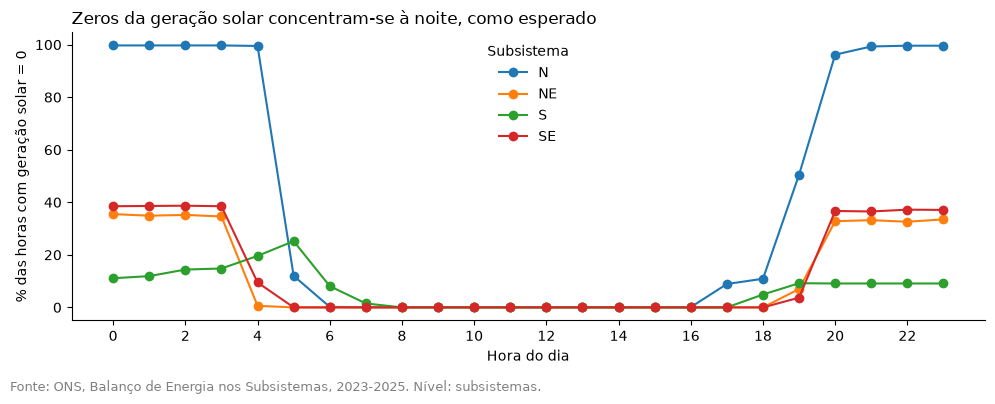

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
for sub in zeros_solares.columns:
    ax.plot(zeros_solares.index, zeros_solares[sub], marker="o", label=sub)
ax.set_title("Zeros da geração solar concentram-se à noite, como esperado", loc="left")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("% das horas com geração solar = 0")
ax.set_xticks(range(0, 24, 2))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Subsistema", frameon=False)
fig.text(0.01, 0.01, "Fonte: ONS, Balanço de Energia nos Subsistemas, 2023-2025. Nível: subsistemas.", fontsize=9, color="gray")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(PASTA_FIGURAS / "01_zeros_solares_por_hora.png", dpi=150)
plt.show()

**Leitura:** os zeros da solar ficam nas horas noturnas e não são ausência de dado. Duas coisas observadas aqui **precisam de investigação na Fase 3**, sem remoção automática:

1. À noite, a solar quase sempre vem com **pequenos valores positivos**, e não com zero (mediana de 0,3 a 1,0 MWmed no NE, S e SE). Há também **picos noturnos isolados de até ~2.900 MWmed**, que não são fisicamente plausíveis para geração solar.
2. Há **5 horas com solar = 0 entre 10h e 14h**, todas no Norte em 2024.

Esses pontos entram na investigação de extremos (DA-006).

## 9. Exportação das tabelas de diagnóstico

In [ ]:
resumo.to_csv(PASTA_TABELAS / "01_resumo_qualidade.csv")
grade.to_csv(PASTA_TABELAS / "01_grade_temporal.csv")
sin_vs_soma.to_csv(PASTA_TABELAS / "01_sin_vs_soma_subsistemas.csv")
identidade.to_csv(PASTA_TABELAS / "01_identidade_balanco_intercambio.csv")
zeros_solares.to_csv(PASTA_TABELAS / "01_zeros_solares_por_hora.csv")
sorted(p.name for p in PASTA_TABELAS.glob("01_*"))

['01_grade_temporal.csv',
 '01_identidade_balanco_intercambio.csv',
 '01_resumo_qualidade.csv',
 '01_sin_vs_soma_subsistemas.csv',
 '01_zeros_solares_por_hora.csv']

: 

## 10. Síntese do diagnóstico (para as tabelas 4.1 e 4.2 do roteiro)

| Aspecto verificado | Resultado encontrado | Ação |
|---|---|---|
| Valores ausentes | 0 em todas as colunas | Nenhuma imputação necessária |
| Duplicidades | 0 linhas e 0 chaves `id_subsistema + din_instante` | Nenhuma remoção |
| Tipos e formatos | CSV UTF-8 `;`; `din_instante` convertido para datetime | Conversão documentada em `src/carregar_dados.py` |
| Cobertura | 26.304 horas por entidade, sem lacunas nem passos irregulares | Série horária contínua |
| Categorias | 5 ids com 1 nome cada; SIN = soma dos subsistemas | Analisar SIN e subsistemas separadamente |
| Negativos | Somente em `val_intercambio` | Esperado; sinal: positivo = exportação líquida |
| Zeros | Concentrados na solar noturna | Não tratar como ausência; investigar zeros diurnos |
| Extremos | Não investigados nesta fase | Fase 3: investigar no contexto, sem remoção automática |

**Pendências que passam para a Fase 2:** investigar e sinalizar os valores suspeitos da solar; confirmar o significado do intercâmbio do SIN (soma dos saldos dos subsistemas, diferente de zero).